# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 5a: TextCNN - Skema 1 "Embeddings"
Vocabulary kata dari train -> `nn.Embedding` 128-dim (acak, dilatih end-to-end) -> Conv1D (kernel 3/4/5) -> max-over-time -> Dropout -> Fully Connected -> softmax

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json`
- Output: `outputs/textcnn_embeddings_val_results.json`, `data/vocab_nn.json`, `outputs/models/textcnn_embeddings.pt`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [ ]:
import os, json, re, random, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
MODEL_DIR = "outputs/models"
RESULT_PATH = "outputs/textcnn_embeddings_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

# Skema 1: tokenisasi level kata, sama dengan Part 04b (kata + tanda baca/emotikon jadi token sendiri)
TOKEN_PATTERN = r"\w+|[^\w\s]"
MIN_FREQ = 2 # token muncul < 2x di train -> <unk>
MAX_LEN = 64 # panjang urutan tetap

# Hyperparameter TETAP (tanpa tuning)
EMB_DIM = 128
NUM_FILTERS = 100 # jumlah filter per ukuran kernel
KERNEL_SIZES = (3, 4, 5) # n-gram 3, 4, 5 token
DROPOUT = 0.5
BATCH_SIZE = 64
EPOCHS = 15 # (range yang diminta: 10-15)
LR = 1e-3 # Adam


for d in (FIG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
NUM_CLASSES = len(labels)
assert all(label_map[l] == i for i, l in enumerate(labels))
y_train = torch.tensor([label_map[l] for l in train_df[LABEL_COL]], dtype=torch.long)
y_val = torch.tensor([label_map[l] for l in val_df[LABEL_COL]], dtype=torch.long)
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 2 - Tokenisasi level kata & vocabulary (hanya dari train)
Indeks 0 = `<pad>`, indeks 1 = `<unk>`. Token di validation yang tidak ada di vocabulary train menjadi `<unk>`.

In [2]:
TOKEN_RE = re.compile(TOKEN_PATTERN)
def tokenize(text):
    return TOKEN_RE.findall(text)

train_tokens = [tokenize(t) for t in train_df[TEXT_COL]]
val_tokens = [tokenize(t) for t in val_df[TEXT_COL]]

# Vocabulary level kata: hanya dari train
counter = Counter(tok for t in train_tokens for tok in t)
itos = ["<pad>", "<unk>"] + sorted(w for w, c in counter.items() if c >= MIN_FREQ)
stoi = {w: i for i, w in enumerate(itos)}
PAD_IDX, UNK_IDX = stoi["<pad>"], stoi["<unk>"]
VOCAB_SIZE = len(itos)

# Vocabulary dibagi bersama untuk TextCNN Embeddings (05a) dan BiLSTM Embeddings (06a)
# --> simpan, atau cek identik jika sudah ada
vp = f"{DATA_DIR}/vocab_nn.json"
if os.path.exists(vp):
    with open(vp, encoding="utf-8") as f: old = json.load(f)["itos"]
    print("Vocabulary identik dengan vocab_nn.json yang sudah ada:", old == itos)
else:
    with open(vp, "w", encoding="utf-8") as f:
        json.dump({"itos": itos, "min_freq": MIN_FREQ, "token_pattern": TOKEN_PATTERN}, f, ensure_ascii=False)

def encode(tokens):
    ids = [stoi.get(t, UNK_IDX) for t in tokens][:MAX_LEN] # potong jika > MAX_LEN
    return ids + [PAD_IDX] * (MAX_LEN - len(ids)) # pad sampai MAX_LEN

X_train = torch.tensor([encode(t) for t in train_tokens], dtype=torch.long)
X_val = torch.tensor([encode(t) for t in val_tokens], dtype=torch.long)

len_tok = np.array([len(t) for t in train_tokens])
tok_val_flat = [t for ts in val_tokens for t in ts]
cakupan_val = np.mean([t in stoi for t in tok_val_flat])
print(f"Ukuran vocabulary (termasuk <pad>, <unk>): {VOCAB_SIZE}")
print(f"Panjang token train: rata-rata {len_tok.mean():.1f} | persentil 95 = {np.percentile(len_tok, 95):.0f} | maks = {len_tok.max()}")
print(f"Teks train yang terpotong oleh MAX_LEN={MAX_LEN}: {(len_tok > MAX_LEN).mean()*100:.2f}%")
print(f"Cakupan token validation oleh vocabulary: {cakupan_val*100:.2f}%")
print("Bentuk tensor -> X_train:", tuple(X_train.shape), "| X_val:", tuple(X_val.shape))

Vocabulary identik dengan vocab_nn.json yang sudah ada: False
Ukuran vocabulary (termasuk <pad>, <unk>): 5716
Panjang token train: rata-rata 19.5 | persentil 95 = 51 | maks = 82
Teks train yang terpotong oleh MAX_LEN=64: 0.14%
Cakupan token validation oleh vocabulary: 85.55%
Bentuk tensor -> X_train: (4921, 64) | X_val: (1055, 64)


In [3]:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256, shuffle=False)

### Step 3 - Arsitektur TextCNN

In [4]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_classes, num_filters, kernel_sizes, dropout, pad_idx):
        super().__init__()
        # Skema 1: embedding level kata, diinisialisasi acak dan ikut dilatih (end-to-end)
        # Bukan TF-IDF, bukan pre-trained
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, num_filters, k) for k in kernel_sizes])
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), num_classes)

    def forward(self, x): # x: (B, L) indeks token
        e = self.embedding(x).transpose(1, 2) # (B, emb_dim, L)  Conv1d butuh channel di dimensi 1
        feats = [F.relu(conv(e)).max(dim=2).values for conv in self.convs] # tiap: (B, num_filters)
        h = self.dropout(torch.cat(feats, dim=1))
        return self.fc(h) # logits; softmax ada di CrossEntropyLoss

model = TextCNN(VOCAB_SIZE, EMB_DIM, NUM_CLASSES, NUM_FILTERS, KERNEL_SIZES, DROPOUT, PAD_IDX).to(device)
w0 = model.embedding.weight.detach().clone() # untuk bukti bahwa embedding ikut dilatih
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

with torch.no_grad():
    out = model(X_train[:4].to(device))
assert out.shape == (4, NUM_CLASSES)
print("Forward pass OK -> output:", tuple(out.shape))
print(f"Parameter yang dilatih: {n_params:,} (embedding: {model.embedding.weight.numel():,})")
print("Embedding trainable:", model.embedding.weight.requires_grad)

Forward pass OK -> output: (4, 6)
Parameter yang dilatih: 887,354 (embedding: 731,648)
Embedding trainable: True


### Step 4 - Training (satu run, tetap 15 epoch, model epoch terakhir yang dievaluasi)
Loss: `CrossEntropyLoss` (tanpa class weight)  
Optimizer Adam lr 1e-3  
Tidak memilih epoch terbaik di validation, supaya validation tidak dipakai untuk seleksi  
Akan ditunjukkan lewat grafik jika seandainya terjadi overfitting

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR) # hanya parameter yang dilatih

def run_epoch(loader, train):
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward()
                optimizer.step()
            tot_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")
print(f"Selesai dalam {time.time()-t0:.0f} detik")

torch.save(model.state_dict(), f"{MODEL_DIR}/textcnn_embeddings.pt")

Epoch  1/15 | train loss 1.4952 acc 0.4314 | val loss 1.1008 acc 0.6047
Epoch  2/15 | train loss 1.0307 acc 0.6428 | val loss 0.9675 acc 0.6692
Epoch  3/15 | train loss 0.8684 acc 0.7064 | val loss 0.9115 acc 0.6787
Epoch  4/15 | train loss 0.7362 acc 0.7474 | val loss 0.9004 acc 0.6853
Epoch  5/15 | train loss 0.6357 acc 0.7807 | val loss 0.8785 acc 0.6919
Epoch  6/15 | train loss 0.5522 acc 0.8104 | val loss 0.8671 acc 0.6976
Epoch  7/15 | train loss 0.5046 acc 0.8267 | val loss 0.8903 acc 0.6872
Epoch  8/15 | train loss 0.4178 acc 0.8606 | val loss 0.9023 acc 0.6995
Epoch  9/15 | train loss 0.3745 acc 0.8742 | val loss 0.8919 acc 0.6938
Epoch 10/15 | train loss 0.3193 acc 0.8996 | val loss 0.9103 acc 0.6872
Epoch 11/15 | train loss 0.2871 acc 0.9067 | val loss 0.9255 acc 0.6976
Epoch 12/15 | train loss 0.2494 acc 0.9201 | val loss 0.9348 acc 0.7014
Epoch 13/15 | train loss 0.2179 acc 0.9303 | val loss 0.9470 acc 0.7014
Epoch 14/15 | train loss 0.2074 acc 0.9372 | val loss 0.9705 acc

In [6]:
# Bukti: embedding Skema 1 benar-benar ikut dilatih (bobotnya berubah dari inisialisasi acak)
print("Embedding berubah setelah training:", not torch.equal(w0, model.embedding.weight.detach()))

Embedding berubah setelah training: True


### Step 5 - Kurva training vs validation (loss & accuracy)

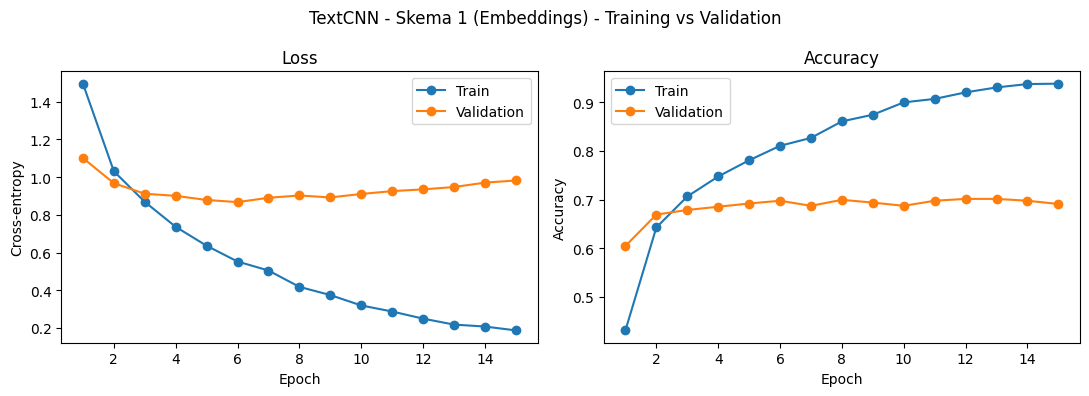

Val loss terendah di epoch 6 (0.8671); epoch terakhir: 0.9818


In [7]:
ep_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ep_axis, history["train_loss"], "o-", label="Train")
axes[0].plot(ep_axis, history["val_loss"], "o-", label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(ep_axis, history["train_acc"], "o-", label="Train")
axes[1].plot(ep_axis, history["val_acc"], "o-", label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
fig.suptitle("TextCNN - Skema 1 (Embeddings) - Training vs Validation")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05a_textcnn_embeddings_curves.png", dpi=150)
plt.show()

best_ep = int(np.argmin(history["val_loss"])) + 1
print(f"Val loss terendah di epoch {best_ep} ({min(history['val_loss']):.4f}); epoch terakhir: {history['val_loss'][-1]:.4f}")

### Step 6 - Evaluasi di validation set (model epoch terakhir)

In [ ]:
model.eval()
preds = []
with torch.no_grad():
    for xb, _ in val_loader:
        preds.append(model(xb.to(device)).argmax(1).cpu())
pred_idx = torch.cat(preds).numpy()

y_val_str  = val_df[LABEL_COL].values
y_pred_str = np.array([labels[i] for i in pred_idx])

acc = accuracy_score(y_val_str, y_pred_str)
macro_p = precision_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_r = recall_score(y_val_str, y_pred_str, average="macro", zero_division=0)
macro_f1 = f1_score(y_val_str, y_pred_str, average="macro")

kelas_terbanyak = train_df[LABEL_COL].value_counts().idxmax()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {(val_df[LABEL_COL] == kelas_terbanyak).mean():.4f}")
print(f"TextCNN - Skema 1 (Embeddings) (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")

# Satu tabel: per kelas + accuracy + macro avg + weighted avg
rapor = classification_report(y_val_str, y_pred_str, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val_str)] # accuracy ditulis di kolom f1-score (konvensi sklearn)
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
TextCNN - Skema 1 (Embeddings) (val): accuracy = 0.6910 | macro-F1 = 0.6996


,precision,recall,f1-score,support
anger,0.7125,0.6786,0.6951,168
fear,0.7667,0.6765,0.7188,136
joy,0.7333,0.6402,0.6836,189
love,0.6054,0.7876,0.6846,113
neutral,0.6294,0.6611,0.6448,298
sad,0.7733,0.7682,0.7708,151
accuracy,,,0.6910,1055
macro avg,0.7034,0.702,0.6996,1055
weighted avg,0.697,0.691,0.6916,1055


### Step 7 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,114,6,3,13,27,5
asli_fear,9,92,4,3,25,3
asli_joy,9,7,121,17,30,5
asli_love,3,0,6,89,14,1
asli_neutral,21,13,27,20,197,20
asli_sad,4,2,4,5,20,116


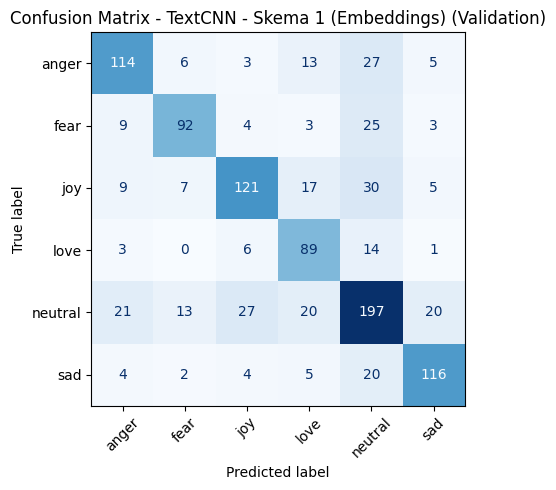

In [9]:
cm = confusion_matrix(y_val_str, y_pred_str, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - TextCNN - Skema 1 (Embeddings) (Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05a_textcnn_embeddings_confusion_matrix_val.png", dpi=150)
plt.show()

### Step 8 - Simpan hasil

In [10]:
# Format JSON seragam (kunci inti sama: model, feature_extraction, split, accuracy, dll)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "TextCNN", "feature_extraction": "embeddings", "split": "validation",
               "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
               "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
               "extractor": "nn.Embedding level kata 128-dim (acak, trainable, end-to-end)",
               "emb_dim": int(EMB_DIM), "max_len": int(MAX_LEN), "vocab_size": int(VOCAB_SIZE),
               "epochs": EPOCHS, "n_trainable_params": int(n_params), "evaluated_epoch": "last"}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

Tersimpan: outputs/textcnn_embeddings_val_results.json


### Notes Part 5a:
- Vocabulary | MAX_LEN | parameter dilatih: 5716 | 64 | 887,354
- Train acc | Val acc (epoch terakhir): 0.9380 | 0.6910
- Val loss terendah di epoch: epoch ke-6 (epoch terakhir: 15)
- Accuracy | Macro-F1 (validation): 0.6910 | 0.6996
- Macro-Precision | Macro-Recall: 0.7034 / 0.7020
- F1 tertinggi | terendah per kelas: sad (0.7708) / neutral (0.6448)
- Pasangan kelas yang paling sering tertukar: joy dan neutral (57 kesalahan di dua arah)
- Test set belum disentuh.